## *ANÁLISIS ENSEMBLES RETÍCULO*


In [1]:
import numpy as np
from numpy import linalg as la
import h5py
import matplotlib.pyplot as plt  
import gvar as gv      #este paquete es útil para variables gaussianas
import lsqfit
from lsqfit import nonlinear_fit
from scipy.special import gammaincc as gammaQ
from scipy.special import gammaln as gammaLn
from scipy.special import gamma as gamma
from IPython.display import display, Math


Los datos se encuentran en una carpeta llamada Ensembles. Para acceder a ellos, tenemos que abrir el archivo hdf5 correspondiente.
Para ello, usamos myFile = h5py.File(ensFile, 'r').

Primero, tenemos que escribir ensFile. 

Nuestro archivo se encuentra dentro de la carpeta Ensembles y de la carpeta FnalHISQ. Ahí, tenemos varias carpetas según el espaciado de la red con el que se han obtenido los datos. Nos interesa un espaciado de 0.12, así que entramos en a0.12.
El archivo que nos interesa se llama: l3264f211b600m00507m0507m628-HISQscript.hdf5 

El nombre nos determina algunas variables:

    - l32: el tamaño espacial del retículo es L=32.
    - 64: el tamaño temporal del retículo es T=64
    - f211: el número de sabores de quarks en el mar (fluctuaciones cuánticas). Intervienen dos quarks ligeros (misma masa), el strange y el charm (2+1+2).
    - b600: el acoplo al que se ha realizado la simulación es b=6.00. Este está relacionado con el espaciado, ya que un acoplo más débil corresponde a energías más altas y, por tanto, a distancias más pequeñas. Este también depende de la acción que se utilice.
    - m00507m0507m628: las masas de los quarks ligeros, strange y charm son 0.00507, 0.0507 y 0.628 respectivamente. Esto fija la masa de los quarks ligeros a 1/10 de la masa del quark extraño. La masa física de los quarks ligeros (asumiendo degeneración) está cerca de 1/27 de la masa del quark extraño. Para los quarks s y c, la masa está ajustada para que coincida con la física. Todas estas masas son del sea. Las masas de valencia, que se usan para calcular funciones de correlación, pueden ser distintas.



In [2]:
ensFile= "../Ensembles/FnalHISQ/a0.12/l3264f211b600m00507m0507m628-HISQscript.hdf5"

Comprobamos que existe:

In [3]:
import os
print(os.path.exists(ensFile))

True


Abrimos nuestro archivo

In [4]:
myFile = h5py.File(ensFile, 'r')

En la carpeta 'data' hay muchos arrays de tipo Dataset {1000/Inf, 64}, lo cual significa que tenemos un array de tamaño 1000x64 y la parte de 1000 es extensible hasta infinito.
El 1000 son las configuraciones que tenemos, y el 64 es la coordenada temporal, así que por cada configuración tenemos una función de correlación que va de t=0 hasta t=63.

Puedo leer los datos accediendo a “myFile” así:

data = numpy.array(myFile[‘data’][NOMBREDELCORRELADOR])

El nombre del correlador es una string, es decir, algo así como “P5_P5_1S_RW_1S_d_k0.12201_m0.00507_p000” (con comillas incluidas).

Para saber cuál tiene que ser el nombre, seguimos las siguientes instrucciones:

- Los primeros dos términos se refieren al tipo de partículas. Tanto los mesones B como D son pseudoescalares, por lo que usamos P5_P5.
- Los siguientes cuatro términos se refieren al smearing aplicado. Los dos primeros se refieren a la fuente y los otros dos al sumidero, en ambos casos refiriéndose primero al mesón B y después al mesón D. Para el mesón B fijamos 1S en ambos puntos. Para el D, podemos trabajar con 1S (parecido a una gaussiana) o RW (random wall) en la fuente y 1S o d (puntual) en el sumidero.
- Los dos sigueintes se refieren a la masa de los quarks del mesón B, que nos sirve para identificarlos. Una tiene que ser la del quark ligero, es decir, 0.00507. La otra se relaciona con el quark pesado, que la estudiamos mediante el parámetro kappa k= 1/(2(4+m)). Tenemos 0.08574 para el b y 0.12201 para el c.
- El último término es el momento del mesón, nosotros vamos a usar momento 0.

Probamos a extraer los datos de un ensemble.

In [5]:
nomCor="P5_P5_1S_RW_1S_d_k0.12201_m0.00507_p000"

In [6]:
data = np.array(myFile['data'][nomCor])

Verificamos las dimensiones:

In [7]:
print(data.shape)

(1000, 64)


Vamos a empezar con el analisis, para ello, necesitamos los nombres de correlacion de las distintas funciones a estudiar.

B (b + q ligero)

In [8]:
ncB="P5_P5_1S_RW_1S_d_k0.08574_m0.00507_p000"

Bs (b + q strange)

In [9]:
ncBs="P5_P5_1S_RW_1S_d_k0.08574_m0.0507_p000"

D (c + q ligero) 

In [10]:
ncD="P5_P5_1S_RW_1S_d_k0.12201_m0.00507_p000"

Ds (c + q strange)

In [11]:
ncDs="P5_P5_1S_RW_1S_d_k0.12201_m0.0507_p000"

Vamos a empezar trabajando con el mesón B.

In [12]:
dataB = np.array(myFile['data'][ncB])

In [13]:
print(dataB.shape)

(1000, 64)


Hemos extraido todos los datos que nos interesan. Queremos realizar el promedio de estos, de tal forma que obtendremos un array unidimensional de promedios de dimension 64.

Para hacer los promedios, utilizamos:

    numpy.mean(a, axis=None, dtype=None, out=None, keepdims=False)

Asimismo, también vamos a calcular la función de covarianza.

In [14]:
medB=np.mean(dataB, axis=0)
covB=np.cov(dataB,rowvar=False)
#print(covB)
errB=np.diag(covB)
#print(errB)
errB=np.sqrt(errB)

In [15]:
print(medB.shape)

(64,)


Ahora vamos a representar la función de correlación en escala logarítmica como función del tiempo. Incluimos errores que obtenemos tomando la raíz cuadrada de la diagonal de la matriz de covarianza. La caída es exponencial, por lo que esperamos ver una línea recta.

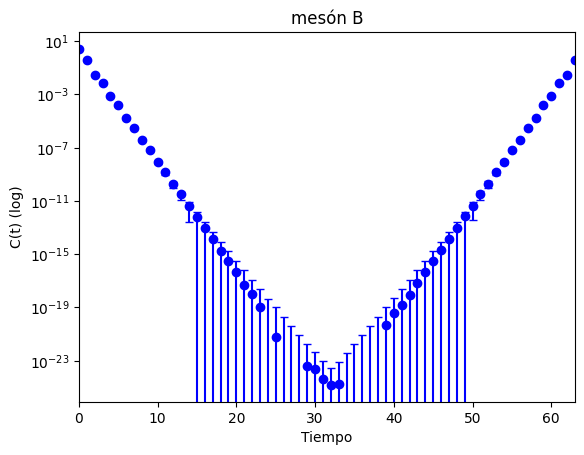

In [16]:
t=range(len(medB))
plt.errorbar(t, medB, yerr=errB, xerr=None, fmt='o', color='blue', ecolor='blue', capsize=3)
plt.xlim(0,63)
plt.yscale("log")
plt.title("mesón B")
plt.xlabel("Tiempo")
plt.ylabel("C(t) (log)")
plt.show()

In [17]:
print(medB.shape)

(64,)


**MESON Bs**

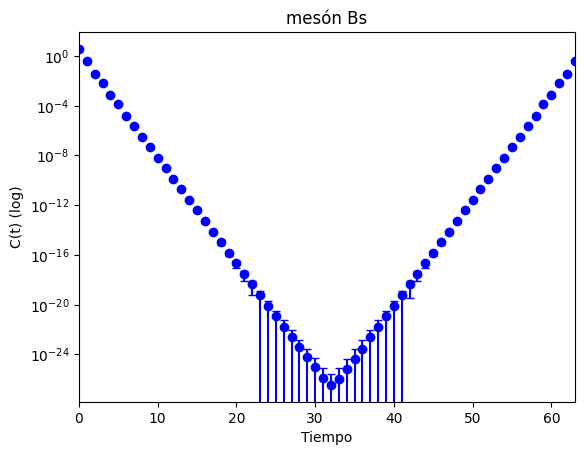

In [18]:
#calculo promedios
dataBs = np.array(myFile['data'][ncBs])
medBs=np.mean(dataBs, axis=0)

#calculo errores
covBs=np.cov(dataBs,rowvar=False)
#print(covB)
errBs=np.diag(covBs)
#print(errB)
errBs=np.sqrt(errBs)

#gráfica
t=range(len(medBs))
plt.errorbar(t, medBs, yerr=errBs, xerr=None, fmt='o', color='blue', ecolor='blue', capsize=3)
plt.xlim(0,63)
plt.yscale("log")
plt.title("mesón Bs")
plt.xlabel("Tiempo")
plt.ylabel("C(t) (log)")
plt.show()

**MESON D**

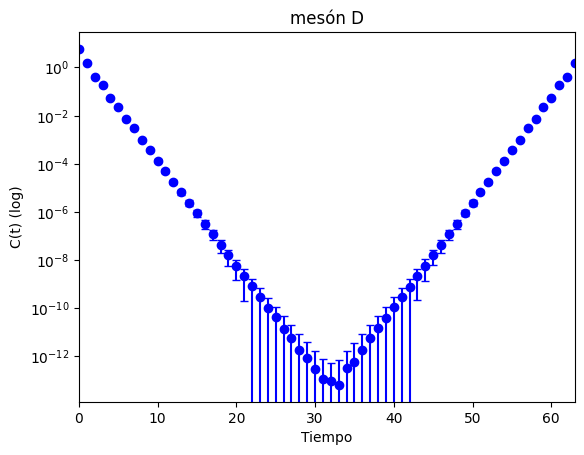

In [19]:
#calculo promedios
dataD = np.array(myFile['data'][ncD])
medD=np.mean(dataD, axis=0)

#calculo errores
covD=np.cov(dataD,rowvar=False)
#print(covB)
errD=np.diag(covD)
#print(errB)
errD=np.sqrt(errD)

#gráfica
t=range(len(medD))
plt.errorbar(t, medD, yerr=errD, xerr=None, fmt='o', color='blue', ecolor='blue', capsize=3)
plt.xlim(0,63)
plt.yscale("log")
plt.title("mesón D")
plt.xlabel("Tiempo")
plt.ylabel("C(t) (log)")
plt.show()

**MESON Ds**

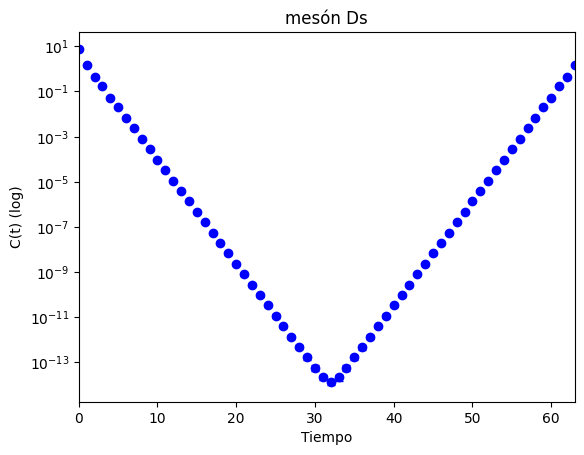

In [20]:
#calculo promedios
dataDs = np.array(myFile['data'][ncDs])
medDs=np.mean(dataDs, axis=0)

#calculo errores
covDs=np.cov(dataDs,rowvar=False)
#print(covB)
errDs=np.diag(covDs)
#print(errB)
errDs=np.sqrt(errDs)

#gráfica
t=range(len(medDs))
plt.errorbar(t, medDs, yerr=errDs, xerr=None, fmt='o', color='blue', ecolor='blue', capsize=3)
plt.xlim(0,63)
plt.yscale("log")
plt.title("mesón Ds")
plt.xlabel("Tiempo")
plt.ylabel("C(t) (log)")
plt.show()

Vamos a hacer una grafica en la que veamos las cuatro a la vez.

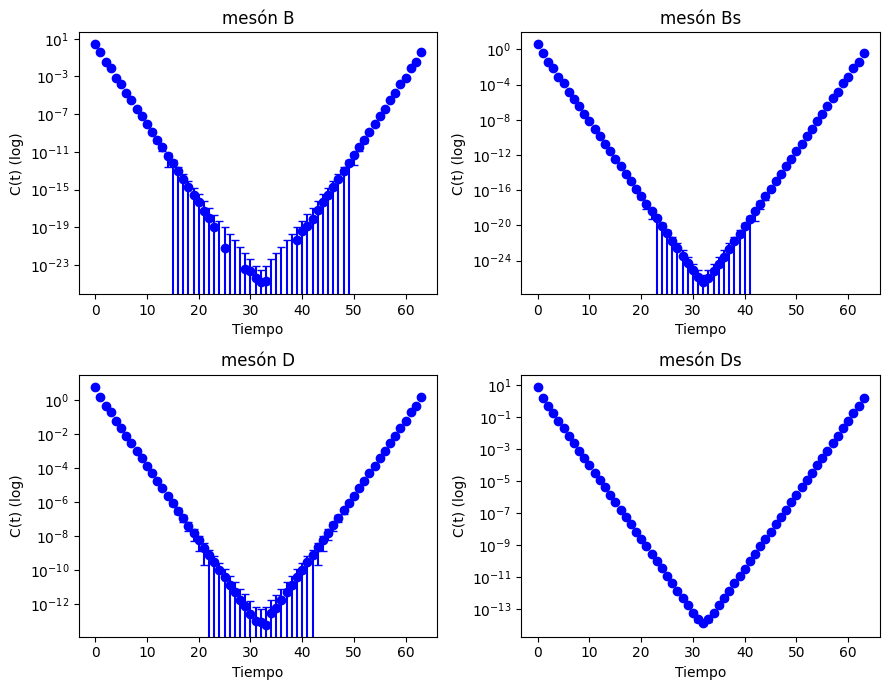

In [21]:
fig, axs = plt.subplots(2, 2, figsize=(9, 7))

axs[0, 0].errorbar(t, medB, yerr=errB, xerr=None, fmt='o', color='blue', ecolor='blue', capsize=3)
axs[0, 0].set_title("mesón B")
axs[0, 0].set_xlabel("Tiempo")
axs[0, 0].set_ylabel("C(t) (log)")
axs[0, 0].set_yscale("log")

axs[0, 1].errorbar(t, medBs, yerr=errBs, xerr=None, fmt='o', color='blue', ecolor='blue', capsize=3)
axs[0, 1].set_title("mesón Bs")
axs[0, 1].set_xlabel("Tiempo")
axs[0, 1].set_ylabel("C(t) (log)")
axs[0, 1].set_yscale("log")

axs[1,0].errorbar(t, medD, yerr=errD, xerr=None, fmt='o', color='blue', ecolor='blue', capsize=3)
axs[1, 0].set_title("mesón D")
axs[1, 0].set_xlabel("Tiempo")
axs[1, 0].set_ylabel("C(t) (log)")
axs[1, 0].set_yscale("log")

axs[1,1].errorbar(t, medDs, yerr=errDs, xerr=None, fmt='o', color='blue', ecolor='blue', capsize=3)
axs[1, 1].set_title("mesón Ds")
axs[1, 1].set_xlabel("Tiempo")
axs[1, 1].set_ylabel("C(t) (log)")
axs[1, 1].set_yscale("log")

plt.tight_layout()
plt.show()


Para hacer el estudio deseado, no vamos a trabajar directamente con los datos extraidos, sino que estos van a pasar por un resampling con el fin de minimizar la autocorrelación de nuestros datos y posibles problemas y obtener un resultado más exacto. Para ello, vamos a usar el jackknife y el binning.

El binning consiste en reducir tu set de datos haciendo promedios de datos contiguos.  Uno puede definir un tiempo, medido en número de configuraciones que uno genera, que hace que las configuraciones sean independientes. Si este número no es divisor del tamaño del ensemble, se hace un promedio con los datos que sobren. 

Creamos un función que dado un array de datos y el número del bin (cuantas configuraciones promediamos a la vez), nos devuelve los datos con el binning hecho.

In [22]:
def binning (datos, Nbin):
    #primero comprobamos si es divisible
    Nconf=np.size(datos,axis=0)
    #print('Nconf =',Nconf)
    Nt=np.size(datos,axis=1)
    #print('Nt =',Nt)
    div=Nconf//Nbin
    resto=Nconf%Nbin
    #print('Ndiv =',div,'resto =',resto)

    #nuestros nuevos datos tendrán una dimensión de div si resto==0 o div+1 si resto=!0
    if (resto==0):
        dat_bin=np.zeros((div,Nt))
        #print(dat_bin)
    else:
        dat_bin=np.zeros((div+1,Nt))

    
    for p in range(div):
        #para cada fila de la nueva conf, sumamos de la fila p*Nbin a (p+1)*Nbin-1
        #podemos usar M[p*Nbin:(p+1)*Nbin,:], que no tiene en cuenta la última fila
        dat_bin[p,:]=np.sum(datos[p*Nbin:(p+1)*Nbin,:],axis=0)/Nbin

    #ahora ya tendriamos completas las primeras div filas.
    #en caso de ser divisible, ya estaría acabado, vamos a estudiar el caso en que no
    #print(datos-dat_bin)
    
    
    if(resto!=0):
        dat_bin[div]=np.sum(datos[div*Nbin:Nconf,:],axis=0)/resto

    return dat_bin

El jackknife consiste en create otro conjunto de N datos, donde cada nuevo dato es la media de todos los datos quitando uno. La matriz de covarianza se tiene que calcular de manera distinta en este caso. La covarianza correcta es la covarianza naive multiplicada por $(N-1)^2$.

Creamos una función que dado un set de datos te devuelve otro con el jackknife realizado.

In [23]:
def jackknife(datos):
    #me dan datos con la forma [C,T] (C:configuraciones, T:tiempo)
    #hay que crear otra matriz de la misma forma
    Nconf=np.size(datos, axis=0)
    Ntime=np.size(datos, axis=1)
    prom=np.zeros((Nconf,Ntime))
    #ahora vamos a ir completando las configuraciones
    #para ello, empezamos haciendo un array sumando todas las columnas
    suma=np.sum(datos, axis=0) #esto nos da un vector de la suma en cada uno de los 64 tiempos
    for i in range(Nconf):
        prom[i,:]=suma-datos[i,:]

    prom=prom/(Nconf-1)

    #ahora vamos a por la covarianza
    cov=np.cov(prom,rowvar=False)*(Nconf-1)**2

    return prom,cov

Combinamos ambos mecanismos en la función resampling.

In [24]:
def resampling(datos_old,Nbin):
    dat_bin=binning(datos_old,Nbin)
    dat_fin,cov=jackknife(dat_bin)
    return dat_fin,cov

Es importante destacar que para un tamaño de bin = 1, tanto la media como la matriz de covarianza antes y después del jackknife es la misma.


In [25]:
#para comprobarlo, vamos a coger los datos del mesón B
#la media estandar ya la tenemos calculada, medB
#vamos a caldular nuestra nueva matriz con el binning 
datos_B1,cov_B1=resampling(dataB,1)
#calculamos la media
medB1=np.mean(datos_B1, axis=0)
print(medB1-medB)
print(cov_B1-covB)
#print (np.shape(covB))
#print(np.max(medB1-medB))
#print(np.max(cov_B1-covB))
#observamos que nos sale practicamente 0 para ambas matrices

[ 1.77635684e-15  7.21644966e-16 -6.93889390e-18  3.46944695e-18
  0.00000000e+00  0.00000000e+00  1.01643954e-20  0.00000000e+00
 -5.29395592e-22  1.58818678e-22 -1.65436123e-24 -8.27180613e-25
  3.87740912e-25 -1.29246971e-26 -8.07793567e-28 -3.02922588e-28
 -8.83524214e-29  1.57772181e-29  0.00000000e+00 -1.97215226e-31
  1.23259516e-32 -1.54074396e-33  1.92592994e-34  6.01853108e-35
 -3.76158192e-37  1.12847458e-36  9.40395481e-38 -5.87747175e-39
  2.64486229e-38  3.67341985e-39 -3.67341985e-39 -7.34683969e-40
 -6.88766221e-41  0.00000000e+00 -3.67341985e-40  6.88766221e-41
  2.93873588e-38  0.00000000e+00  4.23177966e-37 -1.50463277e-36
  3.00926554e-35 -9.62964972e-35 -7.70371978e-34 -3.08148791e-33
 -6.16297582e-33 -9.86076132e-32  0.00000000e+00  1.41994963e-29
 -2.52435490e-29 -4.03896783e-28 -8.07793567e-28 -3.23117427e-26
 -7.75481824e-26  8.27180613e-25 -6.61744490e-24 -5.29395592e-23
 -2.64697796e-22  2.96461532e-21 -1.01643954e-20  2.16840434e-19
 -1.08420217e-19 -2.60208

La demostración de por qué ocurre esto es la siguiente:

<u> Demostración de que la media y la covarianza no cambian para bin=1: </u>

Para calcular el promedio hacemos:
$$
promedio=\frac{suma filas}{numero filas}
$$

Dado que bin=1, el número de filas no ha cambiado, por lo que nos bastan con comprobar que la suma obtenida es la misma.

$$
S'=\sum_{i=0}^{N-1} \frac{suma-datos[i]}{N-1}=\frac{1}{N-1}\sum_{i=0}^{N-1} suma-datos[i]=\frac{1}{N-1} *( N*suma-\sum_{i=0}^{N-1}datos[i])=
$$

$$
=\frac{1}{N-1}(N*suma-suma)=\frac{(N-1)*suma}{N-1}=suma
$$

Podemos ver que obtenemos lo mismo, por lo que queda comprobado que el promedio es igual.



Ahora tenemos que estudiar la covarianza. Para ello, vamos a ver cómo la calculamos. Usamos la función np.cov(data, rowvar=False), lo que indica que cada columna es una variable (cada columna corresponde a un tiempo).
Por definición:

$$
C_{xy} = \frac{1}{N-1} \sum_{k=0}^{N-1} 
\left( x^{(k)} - \bar{x} \right) 
\left( y^{(k)} - \bar{y} \right)
$$

Donde, $\bar{x}$ es el promedio de la columna y $x^{(k)}$ es el dato correspondiente a la fila $k$ de esa columna.
Para calcular la varianza tras el jackknife, hacemos $cov=np.cov(prom,rowvar=False)*(Nconf-1)^2$, por lo que:

$$
C_{x'y'}' =(N-1)^2 \cdot C_{x'y'}
$$

Donde $C_{x'y'}'$ es la varianza tras el jackknife y $ C_{x'y'}$ la varianza naive.

Vamos a desarrollar $C_{x'y'}$. Como ya hemos demostrado, los promedios quedan igual, por lo que:
$$
C_{x'y'} = \frac{1}{N-1}\sum_{k=0}^{N-1} 
\left( x ' ^{(k)}  - \bar{x}   \right) 
\left( y ' ^{(k)}  - \bar{y}  \right)
$$


Vamos a desarrollar el sumatorio $C_{x'y'}$:
$$
C_{x'y'} = \frac{1}{N-1} \sum_{k=0}^{N-1} 
\left(  x ' ^{(k)} \cdot y ' ^{(k)} - x ' ^{(k)} \cdot \bar{y} - y ' ^{(k)} \cdot \bar{x}  + \bar{x} \cdot  \bar{y}  \right) 
$$
$$
C_{x'y'} = \frac{1}{N-1} \left[
\underbrace {\sum_{k=0}^{N-1} \left(  x ' ^{(k)} \cdot y ' ^{(k)} \right)}_{\text{1}} -
\underbrace {\sum_{k=0}^{N-1} \left( x ' ^{(k)} \cdot \bar{y} \right)}_{\text{2}} - 
\underbrace {\sum_{k=0}^{N-1} \left( y ' ^{(k)} \cdot \bar{x} \right)}_{\text{3}} + 
\underbrace {\sum_{k=0}^{N-1} \left(\bar{x} \cdot  \bar{y}  \right)}_{\text{4}} \right]
$$

Vamos a desarrollar término a término.

1:
$$
\sum_{k=0}^{N-1} \left(  x ' ^{(k)} \cdot x' ^{(k)} \right)=
\sum_{k=0}^{N-1} \left( \frac{N \cdot \bar{x} - x^k}{N-1}\right)\left( \frac{N \cdot \bar{y} - y^k}{N-1} \right)=
\frac{1}{(N-1)^2} \sum_{k=0}^{N-1} \left( N^2\bar{x}\bar{y} - N\bar{x}y^k - N\bar{y}x^k +x^ky^k \right)=
$$

$$
=\frac{1}{(N-1)^2} \left( N^3\bar{x}\bar{y} - N^2\bar{x}\bar{y} - N^2\bar{x}\bar{y} +\sum_{k=0}^{N-1} x^ky^k \right) 
$$


2:
$$
\sum_{k=0}^{N-1} \left( x ' ^{(k)} \cdot \bar{y}\right) = \bar{y} \sum_{k=0}^{N-1} \left( x ' ^{(k)}  \right)=\bar{y}\cdot N \cdot \bar{x'}= N\cdot \bar{x} \bar{y}
$$

3: (análogamente)

$$
\sum_{k=0}^{N-1} \left( y ' ^{(k)} \cdot \bar{x} \right) = N\cdot \bar{x} \bar{y}
$$

4:
$$
\sum_{k=0}^{N-1} \left(\bar{x} \cdot  \bar{y}  \right)=N \cdot \bar{x} \bar{y}
$$



Sumando:

$$
C_{x'y'}=\frac{1}{N-1} \left[ \frac{1}{(N-1)^2} \left( N^3\bar{x}\bar{y} - 2N^2\bar{x}\bar{y} +\sum_{k=0}^{N-1} x^ky^k \right) - N\bar{x}\bar{y} \right]
$$


Ahora, incluimos el factor $(N-1)^2$ para obtener el desarrollo de $C_{x'y'}'$

$$
C_{x'y'}' = \frac{1}{N-1} \left[  N^3\bar{x}\bar{y} - 2N^2\bar{x}\bar{y} +\sum_{k=0}^{N-1} x^ky^k - (N-1)^2 N\bar{x}\bar{y} \right] =
$$

$$
= \frac{1}{N-1} \left[N^3\bar{x}\bar{y} - 2N^2\bar{x}\bar{y} +\sum_{k=0}^{N-1} x^ky^k -N^3\bar{x}\bar{y} +2N^2\bar{x}\bar{y} - N\bar{x}\bar{y} \right] = 
$$
$$
= \frac{1}{N-1} \left[-N\bar{x}\bar{y} + \sum_{k=0}^{N-1} x^ky^k \right]
$$

Por otro lado, si desarrollamos $C_{xy}$:
$$
C_{xy} = \frac{1}{N-1} \sum_{k=0}^{N-1} \left( x^{(k)} - \bar{x} \right) \left( y^{(k)} - \bar{y} \right)=
\frac{1}{N-1} \left( N \cdot \bar{x}\bar{y} - N \cdot \bar{x}\bar{y} - N \cdot \bar{x}\bar{y}  + \sum_{k=0}^{N-1} x^{(k)} y^k \right)=
\frac{1}{N-1} \left(- N \cdot \bar{x}\bar{y}  + \sum_{k=0}^{N-1} x^{(k)} y^k \right)
$$


Como podemos comprobar, hemos llegado a la misma expresión, por lo que queda demostrado que para n=1, la covarianza estándar es igual a la del jacknife.

Ahora tomamos el tiempo de la función de correlación t=10 para estudiar cómo cambia el error con el tamaño de bin. Vamos a probar valores para Nbin del 1 al 20.

In [26]:
#Vamos a estudiar como cambia la correlación para 10 valores de bin.
Nbin=np.arange(1, 21) 
cov_10B=np.zeros(np.size(Nbin)) #calculamos la correlación para cada configuración (filas) para cada bin (columnas) ???
cov_10Bs=np.zeros(np.size(Nbin))
cov_10D=np.zeros(np.size(Nbin))
cov_10Ds=np.zeros(np.size(Nbin))


for i in range (np.size(Nbin)):
    datB,covB=resampling(dataB, Nbin[i])
    #print(datB.shape[0])
    covB=covB/datB.shape[0]
    cov_10B[i]=np.sqrt(covB[10][10])
    
    datBs,covBs=resampling(dataBs, Nbin[i])
    #print(datBs.shape[0])
    covBs=covBs/datBs.shape[0]
    cov_10Bs[i]=np.sqrt(covBs[10][10])
    
    datD,covD=resampling(dataD, Nbin[i])
    #print(datD.shape[0])
    covD=covD/datD.shape[0]
    cov_10D[i]=np.sqrt(covD[10][10])
    
    datDs,covDs=resampling(dataDs, Nbin[i])
    #print(datDs.shape[0])
    covDs=covDs/datDs.shape[0]
    cov_10Ds[i]=np.sqrt(covDs[10][10])



Lo representamos en una gráfica. Para ello, normalizamos los errores por el error en el primer bin. Esta debería aproximarse a un plateau. El valor del bin cerca del plateau es a partir del cuál nuestros valores son independientes, es decir, con ese Nbin conseguimos eliminar la autocorrelación.

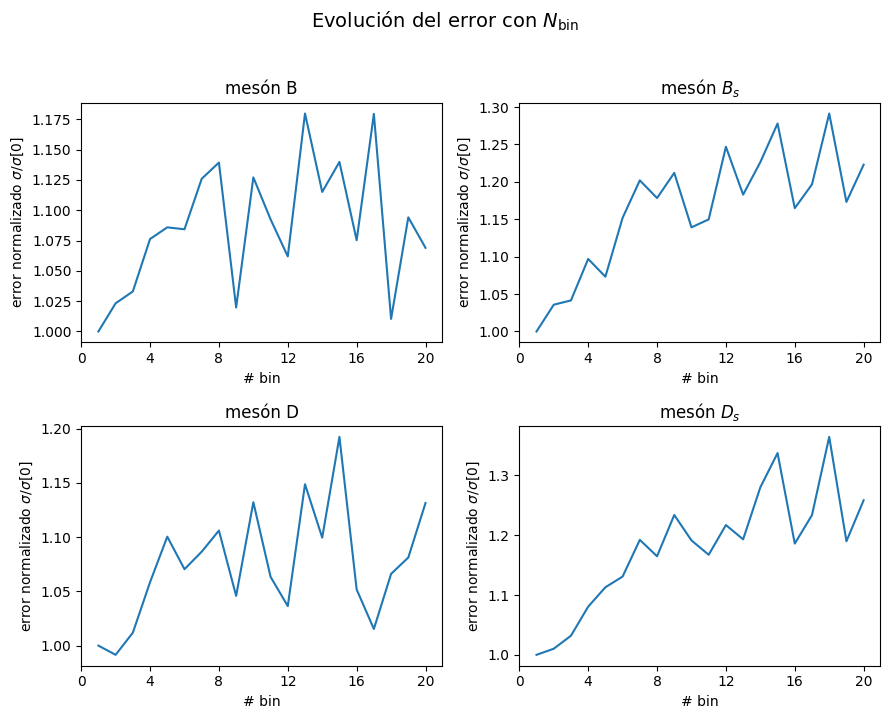

In [27]:
fig, axs = plt.subplots(2, 2, figsize=(9, 7))
fig.suptitle(r"Evolución del error con $N_{\mathrm{bin}}$", fontsize=14, y=1.02)

axs[0, 0].plot(Nbin, cov_10B/cov_10B[0])
axs[0, 0].set_title("mesón B")
axs[0, 0].set_xlabel("# bin")
axs[0, 0].set_ylabel(r"error normalizado $\sigma/\sigma[0]$")
axs[0, 0].set_xticks([0, 4, 8,12,16,20])

axs[0, 1].plot(Nbin, cov_10Bs/cov_10Bs[0])
axs[0, 1].set_title(r"mesón $B_s$")
axs[0, 1].set_xlabel("# bin")
axs[0, 1].set_ylabel(r"error normalizado $\sigma/\sigma[0]$")
axs[0, 1].set_xticks([0, 4, 8,12,16,20])

axs[1, 0].plot(Nbin, cov_10D/cov_10D[0])
axs[1, 0].set_title("mesón D")
axs[1, 0].set_xlabel("# bin")
axs[1, 0].set_ylabel(r"error normalizado $\sigma/\sigma[0]$")
axs[1, 0].set_xticks([0, 4, 8,12,16,20])

axs[1, 1].plot(Nbin, cov_10Ds/cov_10Ds[0])
axs[1, 1].set_title(r"mesón $D_s$")
axs[1, 1].set_xlabel("# bin")
axs[1, 1].set_ylabel(r"error normalizado $\sigma/\sigma[0]$")
axs[1, 1].set_xticks([0, 4, 8,12,16,20])

plt.tight_layout()
plt.savefig("grafica.png", bbox_inches="tight")
plt.show()


Podemos ver que:
- Meson B: Se estabiliza bastante pronto en 5-6, y luego se pone a oscilar alrededor de ese valor.
- Meson Bs: Tarda un poco más en estabilizarse, sobre 8.
- Meson D: Se estabiliza muy pronto, en 5.
- Meson Ds: Sobre 9.

Cogemos para todos el 9 porque es el peor valor y así nos aseguramos. Hay que coger el mismo para todos para facilitarnos el cálculo de las correlaciones entre unos y otros.

Ahora, vamos a pasar a tratar con funciones de correlación a tres puntos. Para extraer $|h_+(1)|$, tal y como se explica en la memoria, es necesario construir un cociente para eliminar así los estados exictados que aparecen, consecuencia del duplicamiento.

Como se explica en la memoria, es necesario tomnar datos con T consecutivos para poder promediar y eliminar los términos oscilantes. Nosotros vamos a tomar datos con T=12 y T=13.

Vamos a empezar por los correladores correspodientes a la desintegración $B \rightarrow D$. Aquí, sabemos que los mesones están ambos formados por un quark espectador (quark ligero: m0.00507) y un quark b que se desintegra en un c. En los correladores, esncontramos primero la masa del quark caracteristico inicial y las dos siguientes son las del quark común y las del quark característico final.

In [28]:
nc3p_12_DB="P5_V4_P5_T12_k0.12201_RW_1S_rot_rot_m0.00507_k0.08574_p000"
nc3p_12_DB_RW="P5_V4_P5_T12_k0.12201_RW_RW_rot_rot_m0.00507_k0.08574_p000"

nc3p_12_BD="P5_V4_P5_T12_k0.08574_RW_1S_rot_rot_m0.00507_k0.12201_p000"
nc3p_12_BD_RW="P5_V4_P5_T12_k0.08574_RW_RW_rot_rot_m0.00507_k0.12201_p000"

nc3p_12_DD="P5_V4_P5_T12_k0.12201_RW_1S_rot_rot_m0.00507_k0.12201_p000"
nc3p_12_DD_RW="P5_V4_P5_T12_k0.12201_RW_RW_rot_rot_m0.00507_k0.12201_p000"

nc3p_12_BB="P5_V4_P5_T12_k0.08574_RW_1S_rot_rot_m0.00507_k0.08574_p000"
nc3p_12_BB_RW="P5_V4_P5_T12_k0.08574_RW_RW_rot_rot_m0.00507_k0.08574_p000"


nc3p_13_DB="P5_V4_P5_T13_k0.12201_RW_1S_rot_rot_m0.00507_k0.08574_p000"
nc3p_13_DB_RW="P5_V4_P5_T13_k0.12201_RW_RW_rot_rot_m0.00507_k0.08574_p000"

nc3p_13_BD="P5_V4_P5_T13_k0.08574_RW_1S_rot_rot_m0.00507_k0.12201_p000"
nc3p_13_BD_RW="P5_V4_P5_T13_k0.08574_RW_RW_rot_rot_m0.00507_k0.12201_p000"

nc3p_13_DD="P5_V4_P5_T13_k0.12201_RW_1S_rot_rot_m0.00507_k0.12201_p000"
nc3p_13_DD_RW="P5_V4_P5_T13_k0.12201_RW_RW_rot_rot_m0.00507_k0.12201_p000"

nc3p_13_BB="P5_V4_P5_T13_k0.08574_RW_1S_rot_rot_m0.00507_k0.08574_p000"
nc3p_13_BB_RW="P5_V4_P5_T13_k0.08574_RW_RW_rot_rot_m0.00507_k0.08574_p000"

Ahora vamos con los correladores de la desintegración $B_s \rightarrow D_s$. Aquí, el quark común es un s (m0.0507).

In [29]:
nc3p_12_DBs="P5_V4_P5_T12_k0.12201_RW_1S_rot_rot_m0.0507_k0.08574_p000"
nc3p_12_DBs_RW="P5_V4_P5_T12_k0.12201_RW_RW_rot_rot_m0.0507_k0.08574_p000"

nc3p_12_BDs="P5_V4_P5_T12_k0.08574_RW_1S_rot_rot_m0.0507_k0.12201_p000"
nc3p_12_BDs_RW="P5_V4_P5_T12_k0.08574_RW_RW_rot_rot_m0.0507_k0.12201_p000"

nc3p_12_DDs="P5_V4_P5_T12_k0.12201_RW_1S_rot_rot_m0.0507_k0.12201_p000"
nc3p_12_DDs_RW="P5_V4_P5_T12_k0.12201_RW_RW_rot_rot_m0.0507_k0.12201_p000"

nc3p_12_BBs="P5_V4_P5_T12_k0.08574_RW_1S_rot_rot_m0.0507_k0.08574_p000"
nc3p_12_BBs_RW="P5_V4_P5_T12_k0.08574_RW_RW_rot_rot_m0.0507_k0.08574_p000"


nc3p_13_DBs="P5_V4_P5_T13_k0.12201_RW_1S_rot_rot_m0.0507_k0.08574_p000"
nc3p_13_DBs_RW="P5_V4_P5_T13_k0.12201_RW_RW_rot_rot_m0.0507_k0.08574_p000"

nc3p_13_BDs="P5_V4_P5_T13_k0.08574_RW_1S_rot_rot_m0.0507_k0.12201_p000"
nc3p_13_BDs_RW="P5_V4_P5_T13_k0.08574_RW_RW_rot_rot_m0.0507_k0.12201_p000"

nc3p_13_DDs="P5_V4_P5_T13_k0.12201_RW_1S_rot_rot_m0.0507_k0.12201_p000"
nc3p_13_DDs_RW="P5_V4_P5_T13_k0.12201_RW_RW_rot_rot_m0.0507_k0.12201_p000"

nc3p_13_BBs="P5_V4_P5_T13_k0.08574_RW_1S_rot_rot_m0.0507_k0.08574_p000"
nc3p_13_BBs_RW="P5_V4_P5_T13_k0.08574_RW_RW_rot_rot_m0.0507_k0.08574_p000"

Calculamos el cociente para ambos valores de T. Luego utilizaremos los dos resultados para eliminar las oscilaciones.

Obtenemos todos los datos necesarios y realizamos el resampling. Dado que bin=11, como hemos visto antes, obtenemos arrays bidimensionales de (91, 64).

In [30]:
num_bin=11

data_12_DB = np.array(myFile['data'][nc3p_12_DB])
data_12_DB_resampling,data_12_DB_cov=resampling(data_12_DB,num_bin)

data_12_BD = np.array(myFile['data'][nc3p_12_BD])
data_12_BD_resampling,data_12_BD_cov=resampling(data_12_BD,num_bin)

data_12_DD = np.array(myFile['data'][nc3p_12_DD])
data_12_DD_resampling,data_12_DD_cov=resampling(data_12_DD,num_bin)

data_12_BB = np.array(myFile['data'][nc3p_12_BB])
data_12_BB_resampling,data_12_BB_cov=resampling(data_12_BB,num_bin)

In [31]:
data_12_DB_RW = np.array(myFile['data'][nc3p_12_DB_RW])
data_12_DB_RW_resampling,data_12_DB_RW_cov=resampling(data_12_DB_RW,num_bin)

data_12_BD_RW = np.array(myFile['data'][nc3p_12_BD_RW])
data_12_BD_RW_resampling,data_12_BD_RW_cov=resampling(data_12_BD_RW,num_bin)

data_12_DD_RW = np.array(myFile['data'][nc3p_12_DD_RW])
data_12_DD_RW_resampling,data_12_DD_RW_cov=resampling(data_12_DD_RW,num_bin)

data_12_BB_RW = np.array(myFile['data'][nc3p_12_BB_RW])
data_12_BB_RW_resampling,data_12_BB_RW_cov=resampling(data_12_BB_RW,num_bin)

In [32]:
data_13_DB = np.array(myFile['data'][nc3p_13_DB])
data_13_DB_resampling,data_13_DB_cov=resampling(data_13_DB,num_bin)

data_13_BD = np.array(myFile['data'][nc3p_13_BD])
data_13_BD_resampling,data_13_BD_cov=resampling(data_13_BD,num_bin)

data_13_DD = np.array(myFile['data'][nc3p_13_DD])
data_13_DD_resampling,data_13_DD_cov=resampling(data_13_DD,num_bin)

data_13_BB = np.array(myFile['data'][nc3p_13_BB])
data_13_BB_resampling,data_13_BB_cov=resampling(data_13_BB,num_bin)

In [33]:
data_13_DB_RW = np.array(myFile['data'][nc3p_13_DB_RW])
data_13_DB_RW_resampling,data_13_DB_RW_cov=resampling(data_13_DB_RW,num_bin)

data_13_BD_RW = np.array(myFile['data'][nc3p_13_BD_RW])
data_13_BD_RW_resampling,data_13_BD_RW_cov=resampling(data_13_BD_RW,num_bin)

data_13_DD_RW = np.array(myFile['data'][nc3p_13_DD_RW])
data_13_DD_RW_resampling,data_13_DD_RW_cov=resampling(data_13_DD_RW,num_bin)

data_13_BB_RW = np.array(myFile['data'][nc3p_13_BB_RW])
data_13_BB_RW_resampling,data_13_BB_RW_cov=resampling(data_13_BB_RW,num_bin)

Hacemos lo mismo para la desintegración $B_s \rightarrow D_s$.

In [34]:
data_12_DBs = np.array(myFile['data'][nc3p_12_DBs])
data_12_DBs_resampling,data_12_DBs_cov=resampling(data_12_DBs,num_bin)

data_12_BDs = np.array(myFile['data'][nc3p_12_BDs])
data_12_BDs_resampling,data_12_BDs_cov=resampling(data_12_BDs,num_bin)

data_12_DDs = np.array(myFile['data'][nc3p_12_DDs])
data_12_DDs_resampling,data_12_DDs_cov=resampling(data_12_DDs,num_bin)

data_12_BBs = np.array(myFile['data'][nc3p_12_BBs])
data_12_BBs_resampling,data_12_BBs_cov=resampling(data_12_BBs,num_bin)

In [35]:
data_12_DBs_RW = np.array(myFile['data'][nc3p_12_DBs_RW])
data_12_DBs_RW_resampling,data_12_DBs_RW_cov=resampling(data_12_DBs_RW,num_bin)

data_12_BDs_RW = np.array(myFile['data'][nc3p_12_BDs_RW])
data_12_BDs_RW_resampling,data_12_BDs_RW_cov=resampling(data_12_BDs_RW,num_bin)

data_12_DDs_RW = np.array(myFile['data'][nc3p_12_DDs_RW])
data_12_DDs_RW_resampling,data_12_DDs_RW_cov=resampling(data_12_DDs_RW,num_bin)

data_12_BBs_RW = np.array(myFile['data'][nc3p_12_BBs_RW])
data_12_BBs_RW_resampling,data_12_BBs_RW_cov=resampling(data_12_BBs_RW,num_bin)

In [36]:
data_13_DBs = np.array(myFile['data'][nc3p_13_DBs])
data_13_DBs_resampling,data_13_DBs_cov=resampling(data_13_DBs,num_bin)

data_13_BDs = np.array(myFile['data'][nc3p_13_BDs])
data_13_BDs_resampling,data_13_BDs_cov=resampling(data_13_BDs,num_bin)

data_13_DDs = np.array(myFile['data'][nc3p_13_DDs])
data_13_DDs_resampling,data_13_DDs_cov=resampling(data_13_DDs,num_bin)

data_13_BBs = np.array(myFile['data'][nc3p_13_BBs])
data_13_BBs_resampling,data_13_BBs_cov=resampling(data_13_BBs,num_bin)

In [37]:
data_13_DBs_RW = np.array(myFile['data'][nc3p_13_DBs_RW])
data_13_DBs_RW_resampling,data_13_DBs_RW_cov=resampling(data_13_DBs_RW,num_bin)

data_13_BDs_RW = np.array(myFile['data'][nc3p_13_BDs_RW])
data_13_BDs_RW_resampling,data_13_BDs_RW_cov=resampling(data_13_BDs_RW,num_bin)

data_13_DDs_RW = np.array(myFile['data'][nc3p_13_DDs_RW])
data_13_DDs_RW_resampling,data_13_DDs_RW_cov=resampling(data_13_DDs_RW,num_bin)

data_13_BBs_RW = np.array(myFile['data'][nc3p_13_BBs_RW])
data_13_BBs_RW_resampling,data_13_BBs_RW_cov=resampling(data_13_BBs_RW,num_bin)

Ahora, aplicamos la ecuación anterior a nuestros datos del array, obteniendo así un cociente para cada bin.

In [38]:
coc_12=(data_12_DB_resampling*data_12_BD_resampling)/(data_12_DD_resampling*data_12_BB_resampling)
coc_12_RW=(data_12_DB_RW_resampling*data_12_BD_RW_resampling)/(data_12_DD_RW_resampling*data_12_BB_RW_resampling)
coc_13=(data_13_DB_resampling*data_13_BD_resampling)/(data_13_DD_resampling*data_13_BB_resampling)
coc_13_RW=(data_13_DB_RW_resampling*data_13_BD_RW_resampling)/(data_13_DD_RW_resampling*data_13_BB_RW_resampling)

In [39]:
coc_12s=(data_12_DBs_resampling*data_12_BDs_resampling)/(data_12_DDs_resampling*data_12_BBs_resampling)
coc_12s_RW=(data_12_DBs_RW_resampling*data_12_BDs_RW_resampling)/(data_12_DDs_RW_resampling*data_12_BBs_RW_resampling)
coc_13s=(data_13_DBs_resampling*data_13_BDs_resampling)/(data_13_DDs_resampling*data_13_BBs_resampling)
coc_13s_RW=(data_13_DBs_RW_resampling*data_13_BDs_RW_resampling)/(data_13_DDs_RW_resampling*data_13_BBs_RW_resampling)

Debido a la presencia de términos oscilantes, vamos a construir un promedio ponderado que elimine la mayor parte de estos $\bar{R}(t,T)$:

$$
\bar{R}(t,T) = \frac{1}{2}R(t,T) + \frac{1}{4}R(t,T+1) + \frac{1}{4}R(t+1,T+1)
$$


Calculamos el $\bar{R}(t,T)$ para cada smearing y canal de desintegración ($B \rightarrow D$
y $B_s \rightarrow D_s$). 

Definimos dos arrays: En el primero metemos el promedio de
R(t,T), y en el segundo su matriz de coviariancia completa (este último
es un array bidimensional).

In [40]:
coc_prom=0.5*coc_12[:,:-1]+0.25*coc_13[:,:-1]+ 0.25* np.roll(coc_13, -1, axis=1)[:,:-1]
coc_prom_RW=0.5*coc_12_RW[:,:-1]+0.25*coc_13_RW[:,:-1]+ 0.25* np.roll(coc_13_RW, -1, axis=1)[:,:-1]

In [41]:
cocs_prom=0.5*coc_12s[:,:-1]+0.25*coc_13s[:,:-1]+ 0.25* np.roll(coc_13s, -1, axis=1)[:,:-1]
cocs_prom_RW=0.5*coc_12s_RW[:,:-1]+0.25*coc_13s_RW[:,:-1]+ 0.25* np.roll(coc_13s_RW, -1, axis=1)[:,:-1]

Ahora, ya tenemos nuestros datos preparados para trabajar con ellos y poder realizar el ajuste.

##### CÓDIGO AJUSTE:

Si asumimos solamente un estado excitado (físico, no oscilante) en fuente y sumidero para cada función a tres puntos, el cociente puede ajustarse como una función $f(t)=r(1+Ae^{-E_1t} +Be^{-E_2(T-t)})$, con $r$ el elemento de matriz (demostración en la memoria). Consecuentemente, podemos obtener el valor de $h_+(1)$ a partir de realizar un ajuste a nuestro cociente.

Para la realización de nuestro ajuste, solo estamos interesados en los datos hasta el tiempo del sumidero (Tsink). Además, vamos a recortar simétricamente nuestros datos eliminar los datos de los extremos y mejorar el ajuste.

Empezamos calculando el cociente y la covarianza de los datos. La covarianza se multiplica por $(N-1)^2$ ya que esos datos han pasado por el jackknife.

In [46]:
Tsink=12
tmin=1

coc_prom_med = np.mean(coc_prom[:,tmin:Tsink-tmin], axis=0)
coc_prom_cov = np.cov(coc_prom[:,tmin:Tsink-tmin], rowvar=False)*(len(coc_prom_med)-1)*(len(coc_prom_med)-1)

coc_prom_RW_med = np.mean(coc_prom_RW[:,tmin:Tsink-tmin], axis=0)
coc_prom_RW_cov = np.cov(coc_prom_RW[:,tmin:Tsink-tmin], rowvar=False)*(len(coc_prom_RW_med)-1)*(len(coc_prom_RW_med)-1)

In [49]:
tmin=2
cocs_prom_med = np.mean(cocs_prom[:,tmin:Tsink-tmin], axis=0)
cocs_prom_cov = np.cov(cocs_prom[:,tmin:Tsink-tmin], rowvar=False)*(len(cocs_prom_med)-1)*(len(cocs_prom_med)-1)

cocs_prom_RW_med = np.mean(cocs_prom_RW[:,tmin:Tsink-tmin], axis=0)
cocs_prom_RW_cov = np.cov(cocs_prom_RW[:,tmin:Tsink-tmin], rowvar=False)*(len(cocs_prom_RW_med)-1)*(len(cocs_prom_RW_med)-1)

Tenemos cuatro secuencias de datos:
- $B \rightarrow D$ con smearing 1S  
- $B \rightarrow D$ sin smearing  
- $B_s \rightarrow D_s$ con smearing 1S  
- $B_s \rightarrow D_s$ sin smearing 

Vamos a hacer un ajuste conjunto de smearings dentro de cada canal, por lo que solo diferenciaremos entre un ajuste para la desintegración $B \rightarrow D$ y otro para $B_s \rightarrow D_s$.

Por ser un ajuste bayesiano, es necesario pasar unos priores. Nuestros priores se han elegido de tal forma que ni fuercen ni sesguen. Es por esto que tienen errores tan grandes.
- r: ponemos un promedio entre el valor central de cada smearing
- E: hemos elegido un valor medio=Lambda_QCD (~ 1 Gev) y le ponemos un error del 100%
- amplitudes: tomamos un valor medio de 0 ya que se supone que no hay estados oscilantes y un error de 1 que, de nuevo, es muy amplio para evitar forzar y sesgar

In [50]:
#primero vamos a preparar nuestros datos
array_t=np.arange(tmin,Tsink-tmin)

t={'RW':array_t,
   '1S':array_t}

datos_BD={'RW': gv.gvar(coc_prom_RW_med, coc_prom_RW_cov),
          '1S': gv.gvar(coc_prom_med,coc_prom_cov)}
datos_BsDs={'RW': gv.gvar(cocs_prom_RW_med, cocs_prom_RW_cov),
          '1S': gv.gvar(cocs_prom_med,cocs_prom_cov)}


#esta es la función a la que se tienen que ajustar nuestros valores
def fcn (x,p):
    return {
        'RW': p['r']*(1 + p['ARW']*np.exp(-p['E']*x['RW']) + p['BRW']*np.exp(-p['E']*(Tsink-x['RW']))),
        '1S': p['r']*(1 + p['A1S']*np.exp(-p['E']*x['1S']) + p['B1S']*np.exp(-p['E']*(Tsink-x['1S'])))}


#calculamos los priores:
mPoint_d = len(datos_BD['RW']) // 2
mPoint_s = len(datos_BD['1S']) // 2
prMid = 0.5*gv.mean((datos_BD['RW'][mPoint_d]+datos_BD['1S'][mPoint_s]))


prior={
    'r':gv.gvar(prMid, 0.15),
    'E': gv.gvar(1.0, 1.0),
    'ARW': gv.gvar( 0.0, 1.0),
    'BRW': gv.gvar( 0.0, 1.0),
    'A1S': gv.gvar( 0.0, 1.0),
    'B1S': gv.gvar( 0.0, 1.0)
}
'''

prior={
    'r':gv.gvar(prMid, 0.15),
    'E': gv.gvar(1.0, 1.0),
    'ARW': gv.gvar( 0.0, 1.0),
    'A1S': gv.gvar( 0.0, 1.0)
}
'''
#ploteamos el ajuste
def plot_fit(fit, npts=200, titulo=None, ax=None):
    if ax is None:
        fig, ax = plt.subplots(figsize=(7, 5))

    x, y = fit.x, fit.y
    colores = plt.rcParams['axes.prop_cycle'].by_key()['color']

    # Malla fina de t para dibujar la curva
    tmin = min(np.min(x[k]) for k in x)
    tmax = max(np.max(x[k]) for k in x)
    tf = np.linspace(tmin, tmax, npts)
    yfit = fit.fcn({k: tf for k in x}, fit.p)   # dict de gvars

    for i, k in enumerate(y):
        c = colores[i % len(colores)]
        ax.errorbar(x[k], gv.mean(y[k]), yerr=gv.sdev(y[k]),
                    fmt='o', color=c, capsize=3, label=f'datos {k}')
        m, s = gv.mean(yfit[k]), gv.sdev(yfit[k])
        ax.plot(tf, m, '-', color=c, label=f'fit {k}')
        ax.fill_between(tf, m - s, m + s, color=c, alpha=0.25)

    ax.set_xlabel('t')
    ax.set_ylabel('y')
    ax.legend()
    ax.set_title(titulo or f'χ²/dof = {fit.chi2:.2f}/{fit.dof}   Q = {fit.Q:.2f}')
    return ax

Empezamos por el ajuste de $B \rightarrow D$:

Least Squares Fit:
  chi2/dof [dof] = 0.6 [20]    Q = 0.91    logGBF = 81.96

Parameters:
              r    1.0075 (51)      [  1.01 (15) ]  
              E      0.45 (31)      [  1.0 (1.0) ]  
            ARW   -0.0215 (64)      [    0 ± 1.0 ]  
            BRW   -0.0070 (97)      [    0 ± 1.0 ]  
            A1S   -0.0087 (48)      [    0 ± 1.0 ]  
            B1S   -0.0050 (82)      [    0 ± 1.0 ]  

Settings:
  svdcut/n = 1e-12/0    tol = (1e-08,1e-10,1e-10*)    (itns/time = 17/0.1s)
  fitter = scipy_least_squares    method = trf



<Axes: title={'center': 'χ²/dof = 12.06/20   Q = 0.91'}, xlabel='t', ylabel='y'>

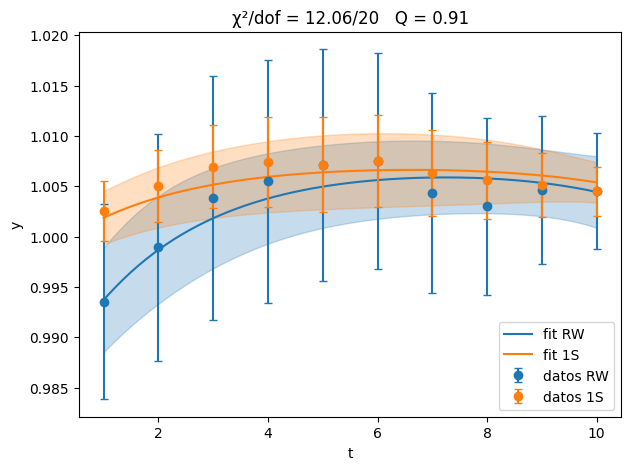

In [48]:
fit_BD= lsqfit.nonlinear_fit(data=(t, datos_BD), prior=prior, fcn=fcn)
print(fit_BD)
plot_fit(fit_BD)

Least Squares Fit:
  chi2/dof [dof] = 1.1 [16]    Q = 0.38    logGBF = 79.447

Parameters:
              r   1.00763 (68)      [  1.01 (15) ]  
              E     0.896 (98)      [  1.0 (1.0) ]  
            ARW   -0.0538 (77)      [    0 ± 1.0 ]  
            BRW    0.0030 (67)      [    0 ± 1.0 ]  
            A1S   -0.0166 (25)      [    0 ± 1.0 ]  
            B1S   -0.0095 (48)      [    0 ± 1.0 ]  

Settings:
  svdcut/n = 1e-12/0    tol = (1e-08,1e-10,1e-10*)    (itns/time = 10/0.0s)
  fitter = scipy_least_squares    method = trf



<Axes: title={'center': 'χ²/dof = 17.15/16   Q = 0.38'}, xlabel='t', ylabel='y'>

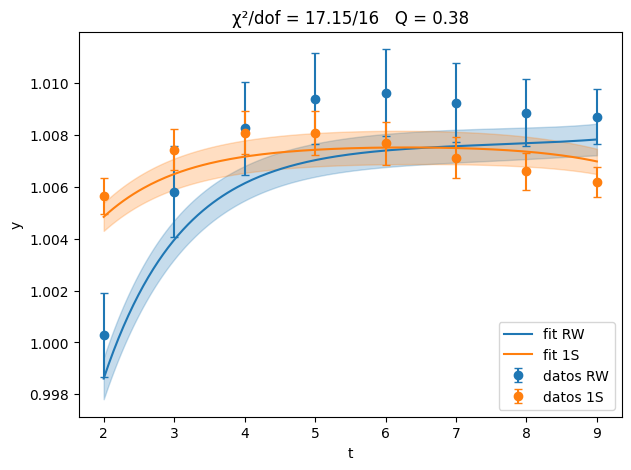

In [51]:
mPoints_d = len(datos_BsDs['RW']) // 2
mPoints_s = len(datos_BsDs['1S']) // 2
prMid_BD = 0.5*gv.mean((datos_BsDs['RW'][mPoint_d]+datos_BsDs['1S'][mPoint_s]))
prior['r']=gv.gvar(prMid, 0.15)


fit_BsDs= lsqfit.nonlinear_fit(data=(t, datos_BsDs), prior=prior, fcn=fcn)
print(fit_BsDs)
plot_fit(fit_BsDs)

In [52]:
r_BD=fit_BD.p['r']
r_BsDs=fit_BsDs.p['r']

Los valores presentados a continuación se han obtenido utilizando amplitudes independientes y un tmin=1 para el $B \rightarrow D$ y un tmin=2 para $Bs \rightarrow Ds$.

In [53]:
print('El parámetro r para la desintegración B->D es:',r_BD)
print('El parámetro r para la desintegración Bs->Ds es:',r_BsDs)

El parámetro r para la desintegración B->D es: 1.0075(51)
El parámetro r para la desintegración Bs->Ds es: 1.00763(68)


Para obtener el valor de $h_{+}(1)$, tenemos que tener en cuenta la ecuación 20, la cuál se verifica, tal y como hemos demostrado antes para tiempos largos, es decir  $t \to \infty$ y $(T-t) \to \infty$. En este límite, nos queda $R(t)=r$, por lo que $h_{+}(1) = \sqrt{r}$.

In [54]:
h_BD=gv.sqrt(r_BD)
h_BsDs=gv.sqrt(r_BsDs)

h_BD, h_BsDs

(1.0037(26), 1.00381(34))

Para obtener el valor de $V_{cb}$, necesitamos extraer ciertos términos de papers, que combinaremos con los cálculos realizados para obtener así el resultado buscado. Obtenemos el valor de $\eta_{EW} G(1) |V_{cb}|$ y el de $\eta_{EW}$.

In [55]:
value=gv.gvar(42.29,1.37)
value_s=gv.gvar(45.6,1.6)
#print(value)
eta=gv.gvar(1.00662,0.00016)
#print(eta)

El valor dde $G(1)$ es el que hemos calculado, por lo que ya podemos despejar $|V_{cb}|$.

In [56]:
Vcb=value/(eta*h_BD)
Vcb_s=value_s/(eta*h_BsDs)

print(Vcb)
print(Vcb_s)

41.9(1.4)
45.1(1.6)


Finalmente, calculamos la diferencia entre nuestros valores.

In [57]:
dif=Vcb_s-Vcb
dif

3.3(2.1)